# Local demo latency: recorded CPU / GPU comparison

This notebook only reads saved JSON and draws charts. It never starts a model, server, training job or API call. The main comparison uses **repeated requests only**: CPU n=1 and GPU n=2. The first CPU measurement used an existing worker; the first GPU measurement followed a restart.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/report_demo_latency.py').is_file())
sys.path.insert(0, str(ROOT))
from scripts.report_demo_latency import build_comparison, plot_speed, plot_stages
CPU = ROOT / 'data\\generated\\demo-latency-cpu\\summary.json'
GPU = ROOT / 'data\\generated\\demo-latency-gpu\\summary.json'
OUT = ROOT / 'data\\generated\\demo-latency-comparison'
OUT.mkdir(parents=True, exist_ok=True)
comparison = build_comparison(CPU, GPU)
print('Recorded audio:', comparison['audio'])
print('No TTS, no external audio, no training. Same submitted WAV SHA256 verified.')

Recorded audio: {'filename': 'e2e-grammar.wav', 'source_sha256': 'af0239e4befbda94da86d3fdc86affd22b115413b777fa36286ec1947fed2947', 'submitted_wav_sha256': '0ff117784ec34f4ba03d5a869a9f408863ca566d13b10533f047c58b71a62997', 'duration_sec': 2.969063, 'sample_rate': 16000}
No TTS, no external audio, no training. Same submitted WAV SHA256 verified.


## Per-request measurements

Same audio and empty history, sampled conversation. Completion-token lengths differ; do not interpret these as a controlled hardware-only comparison. Reply-ready measures a completed reply, not first token.

In [2]:
requests = pd.DataFrame(comparison['runs'])
display(requests[['session','request','group','reply_ready_sec','full_elapsed_sec','normalization_sec','rewrite_sec','completion_tokens']].round(3))
repeat_rows = []
for name, stats in comparison['repeats_only']['sessions'].items():
    repeat_rows.append({'session': name, 'n': stats['n'], 'reply-ready mean (s)': stats['reply_ready_sec']['mean'], 'full mean (s)': stats['full_elapsed_sec']['mean']})
display(pd.DataFrame(repeat_rows).round(3))
print(json.dumps(comparison['repeats_only']['observed_change'], indent=2))

,session,request,group,reply_ready_sec,full_elapsed_sec,normalization_sec,rewrite_sec,completion_tokens
0,CPU FP32/eager,1,first measured request,18.610,24.407,9.765,5.844,10
1,CPU FP32/eager,2,repeat request,8.468,13.281,3.797,4.735,27
2,GPU BF16/SDPA,1,first measured request,25.188,28.485,6.188,3.359,10
3,GPU BF16/SDPA,2,repeat request,2.657,4.469,0.922,1.890,18
4,GPU BF16/SDPA,3,repeat request,2.625,4.438,0.797,1.890,18


,session,n,reply-ready mean (s),full mean (s)
0,CPU FP32/eager,1,8.468,13.281
1,GPU BF16/SDPA,2,2.641,4.454


{
  "reply_ready_sec": {
    "observed_ratio": 3.2063612268080273,
    "reduction_percent": 68.81199811053378
  },
  "full_elapsed_sec": {
    "observed_ratio": 2.9821488716739646,
    "reduction_percent": 66.4671334989835
  }
}


## Repeats-only speed chart

Arithmetic means. One repeated CPU measurement does not establish variability or a confidence interval.

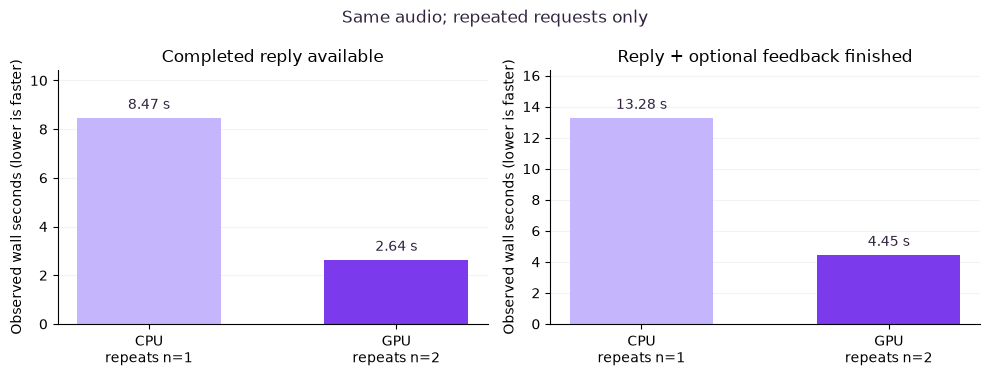

In [3]:
figure = plot_speed(comparison)
figure.savefig(OUT / 'before-after.png', dpi=160, facecolor='white')
plt.show()

## First measured requests: loading and cache effects

**CPU first measured is not a cold start.** The restarted GPU worker took about 25 seconds to publish its first reply; this cost is excluded from the repeats-only means.

In [4]:
display(pd.DataFrame(comparison['first_measured_requests'])[['session','reply_ready_sec','full_elapsed_sec','normalization_sec','completion_tokens']].round(3))
print('First requests are reported separately, never pooled into repeated-request means.')

,session,reply_ready_sec,full_elapsed_sec,normalization_sec,completion_tokens
0,CPU FP32/eager,18.610,24.407,9.765,10
1,GPU BF16/SDPA,25.188,28.485,6.188,10


First requests are reported separately, never pooled into repeated-request means.


## GPU repeated-request stage breakdown

Qwen uses GPU BF16/SDPA; ASR and phoneme-B remain on CPU. Stage timers are unavailable in the older CPU worker. Zero values can reflect cache hits or timer precision. The residual includes IPC, polling and uninstrumented work; measurements are not an exact trace.

request,2,3
stage,,
ASR on CPU,0.344,0.359
Decode audio,0.000,0.016
Grammar + natural wording,1.890,1.890
Other / observation residual,0.094,0.048
Phoneme-B on CPU,0.359,0.375
Pronunciation assessment,0.000,0.000
Qwen reply generation,0.860,0.953
Reference resolution,0.000,0.000
Reference setup,0.000,0.000


,mean seconds
stage,
Decode audio,0.008
ASR on CPU,0.352
Reference setup,0.000
Phoneme-B on CPU,0.367
Pronunciation assessment,0.000
Reference resolution,0.000
Sound-neighbour lookup,0.000
Transcript normalization,0.860
Qwen reply generation,0.906


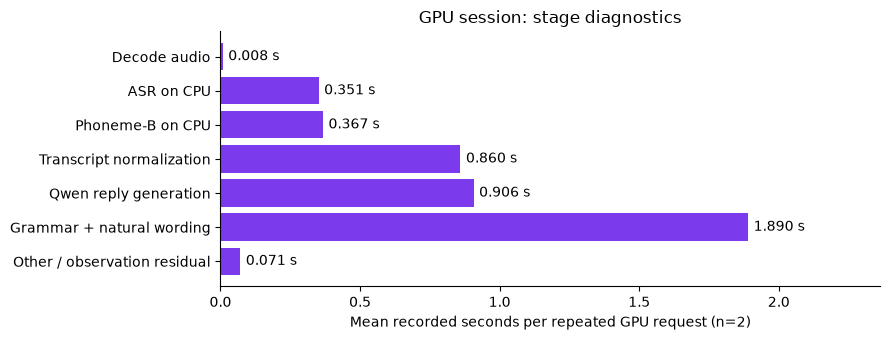

In [5]:
stage_rows = pd.DataFrame(comparison['gpu_repeat_stage_measurements'])
display(stage_rows.pivot(index='stage', columns='request', values='seconds').round(3))
display(stage_rows.groupby('stage', sort=False).seconds.mean().rename('mean seconds').to_frame().round(3))
figure = plot_stages(comparison)
figure.savefig(OUT / 'gpu-stage-breakdown.png', dpi=160, facecolor='white')
plt.show()

## Limits and provenance

- Small diagnostic only: one repeated CPU request and two repeated GPU requests on one 2.97-second synthetic English recording; not a speech-quality benchmark.
- The primary comparison excludes each session's first measured request. The CPU worker was already running; its first measured request is not a cold-start measurement. The GPU worker was restarted, and its first measured request took about 25 seconds to publish the reply.
- Repeated audio reuses dictionary, pronunciation and model caches. New words, new audio or a restarted process may take longer. Zero recorded stage time can reflect a warm cache or timer precision, not absence of work.
- Conversation sampling is enabled. CPU and GPU generated different replies and different completion-token counts; these results do not isolate hardware speed or establish a guaranteed speedup.
- Qwen changed from CPU FP32/eager in the existing worker to GPU BF16/SDPA after restart. ASR and phoneme-B remain on CPU with two threads. This compares the full runtime configuration, not GPU alone.
- No voice API was called. ai33/Sarah synthesis, audio download/playback, microphone capture, browser rendering and ngrok network delays are excluded.
- Reply-ready is observed after a completed reply becomes available; it is not time to first generated token. HTTP polling at 0.15 seconds limits wall-clock precision.
- Stage measurements are instrumented only in the GPU session. CPU pure-generation time cannot be recovered from reply_latency_sec, which includes audio analysis and normalization.
- Source hashes in benchmark summaries describe files on disk. The CPU measurement used an older worker already loaded before those files changed; disk hashes do not identify that worker's loaded code.

In [6]:
print(json.dumps({'audio': comparison['audio'], 'provenance': comparison['provenance']}, indent=2))
print('No voice-generation latency or speech-quality result is inferred from these timings.')

{
  "audio": {
    "filename": "e2e-grammar.wav",
    "source_sha256": "af0239e4befbda94da86d3fdc86affd22b115413b777fa36286ec1947fed2947",
    "submitted_wav_sha256": "0ff117784ec34f4ba03d5a869a9f408863ca566d13b10533f047c58b71a62997",
    "duration_sec": 2.969063,
    "sample_rate": 16000
  },
  "provenance": {
    "cpu": {
      "summary_path": "D:\\NCC\\MDD\\data\\generated\\demo-latency-cpu\\summary.json",
      "summary_sha256": "1960a372e47df9b6835247b817866ff70eb2536e2fc920c6b6d0920566a21dac",
      "started_at_utc": "2026-10-23T02:05:53.703779+00:00",
      "config": {
        "device": "cpu",
        "threads": 2,
        "asr_model_id": "wav2vec2-vi-en-v1",
        "grammar_model_id": "qwen-grammar",
        "reply_model_id": "qwen-base",
        "transcript_normalization": "lexical_preserving_v1"
      },
      "poll_interval_sec": 0.15,
      "runtime_source_changed": false,
      "source_files_sha256": {
        "scripts/benchmark_demo_latency.py": "8f29e9d1f315b311ca02d4f5